## 2-5 拟合余弦函数曲线

In [12]:
import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from torch.utils.data import TensorDataset

import numpy as np
import matplotlib
import matplotlib.pyplot as plt


In [13]:
x = np.linspace(-2*np.pi, 2*np.pi, 400)
y = np.cos(x)

X = np.expand_dims(x, axis=1)
Y = y.reshape(400, -1)

dataset = TensorDataset(torch.tensor(X, dtype=torch.float), 
                        torch.tensor(Y, dtype=torch.float))
dataloader = DataLoader(dataset, batch_size=10, shuffle=True)

In [14]:
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features=1, out_features=10),
            nn.ReLU(),
            nn.Linear(10, 100),
            nn.ReLU(),
            nn.Linear(100, 10),
            nn.ReLU(),
            nn.Linear(10, 1),
        )

    def forward(self, input: torch.FloatTensor):
        return self.net(input)


net = Net()

In [15]:
optim = torch.optim.Adam(Net.parameters(net), lr=1e-3)
loss_fn = nn.MSELoss()

In [16]:
for epoch in range(100):
    loss = None
    for batch_x, batch_y in dataloader:
        optim.zero_grad()
        y_predict = net(batch_x)
        loss = loss_fn(y_predict, batch_y)
        loss.backward()
        optim.step()

        if (epoch + 1) % 10 == 0:
            print(f"Training steps: {epoch + 1}, Loss: {loss.item()}")

predict = net(torch.tensor(X, dtype=torch.float))

Training steps: 10, Loss: 0.051593124866485596
Training steps: 10, Loss: 0.03706728667020798
Training steps: 10, Loss: 0.03630802780389786
Training steps: 10, Loss: 0.007397384382784367
Training steps: 10, Loss: 0.04926455765962601
Training steps: 10, Loss: 0.03725769370794296
Training steps: 10, Loss: 0.05627024918794632
Training steps: 10, Loss: 0.05628699064254761
Training steps: 10, Loss: 0.05660124495625496
Training steps: 10, Loss: 0.04759209230542183
Training steps: 10, Loss: 0.04828571155667305
Training steps: 10, Loss: 0.025285357609391212
Training steps: 10, Loss: 0.06226916238665581
Training steps: 10, Loss: 0.010650652460753918
Training steps: 10, Loss: 0.03347453474998474
Training steps: 10, Loss: 0.01073424331843853
Training steps: 10, Loss: 0.04196743667125702
Training steps: 10, Loss: 0.03802754729986191
Training steps: 10, Loss: 0.04437375068664551
Training steps: 10, Loss: 0.05093982815742493
Training steps: 10, Loss: 0.05828000232577324
Training steps: 10, Loss: 0.03

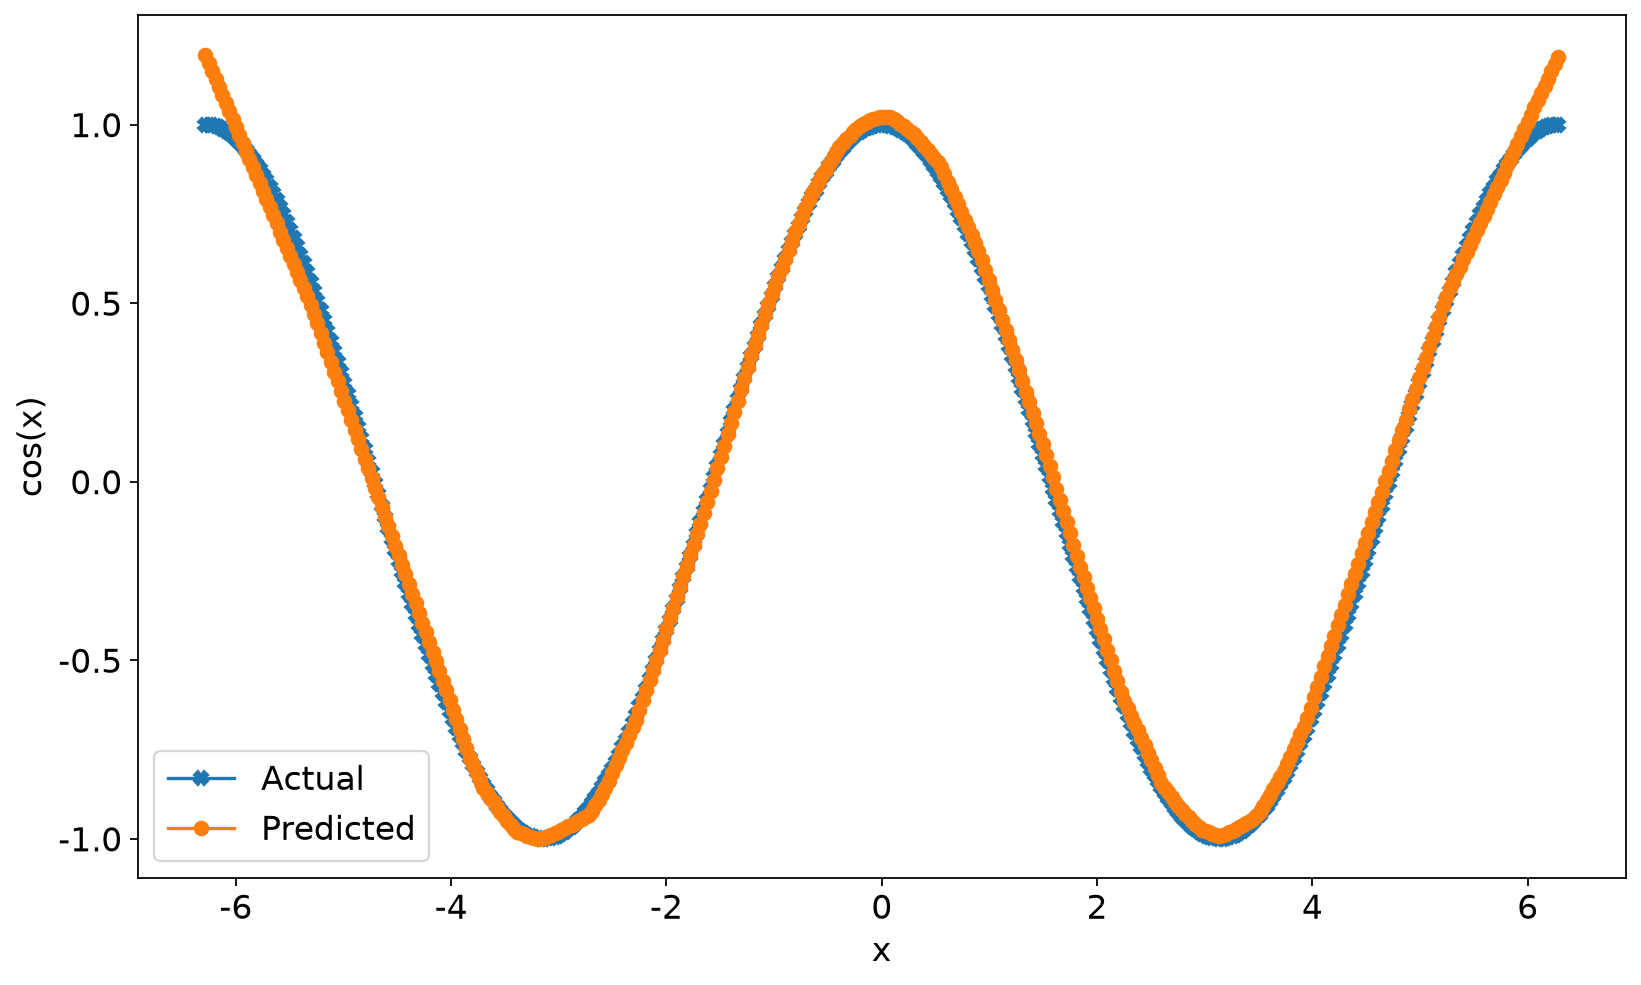

In [25]:
matplotlib.rcParams['font.sans-serif'] = ['DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(12, 7), dpi=160)
plt.plot(x, y, label="Actual", marker="X")
plt.plot(x, predict.detach().numpy(), label="Predicted", marker="o")
plt.xlabel("x", size=15)
plt.xticks(size=15)
plt.ylabel("cos(x)",size=15)
plt.yticks(size=15)
plt.legend(fontsize=15)
plt.show()

## 2-6-1

In [28]:
import torch

a = torch.tensor([[1, 0], [0, 1]])
b = torch.tensor([[0, 1], [1, 0]])

print(f"Add: {torch.add(a, b)}")
print(f"Sub: {torch.sub(a, b)}")
print(f"Mul: {torch.mul(a, b)}")
print(f"Div: {torch.div(a, b)}")

Add: tensor([[1, 1],
        [1, 1]])
Sub: tensor([[ 1, -1],
        [-1,  1]])
Mul: tensor([[0, 0],
        [0, 0]])
Div: tensor([[inf, 0.],
        [0., inf]])


## 2-6-2

In [32]:
import torch

x = torch.tensor([3.0], dtype=float, requires_grad=True)
f_x = x**2 + 2*x + 1

f_x.backward()
print(x.grad.item())

8.0


## 2-6-3

In [49]:
import torch

ten_tensor = torch.randn(10)

print(f"original: {ten_tensor.numpy()}")

print(f"mean value: {ten_tensor.mean().item()}")
print(f"median value: {ten_tensor.median().item()}")
print(f"mode value: {ten_tensor.mode().values.item()}, {ten_tensor.mode().indices.item()}")
print(f"var value: {ten_tensor.var(unbiased=True).item()}")
print(f"std value: {ten_tensor.var(unbiased=True).item()}")

original: [ 0.00396273 -0.15488172 -0.84336376  0.08616829 -2.8301563  -0.3201083
 -1.0140344  -0.0168827   0.5745503   1.3890225 ]
mean value: -0.31257230043411255
median value: -0.15488171577453613
mode value: -2.8301563262939453, 4
var value: 1.2406636476516724
std value: 1.2406636476516724


## 2-6-4

In [52]:
import torch

a = torch.randn((3, 3))
b = torch.randn((1, 3))

print(f"original a: {a.numpy()}")
print(f"original b: {b.numpy()}")

print(f"add result: {torch.add(a, b).numpy()}")
print(f"sub result: {torch.sub(a, b).numpy()}")
print(f"mul result: {torch.mul(a, b).numpy()}")
print(f"div result: {torch.div(a, b).numpy()}")

original a: [[-1.4099112   0.61538327 -0.2711858 ]
 [-1.6308142   1.0473555  -0.43456617]
 [-0.61932087 -0.6992488  -0.46295732]]
original b: [[ 0.01921738  0.6210843  -2.141635  ]]
add result: [[-1.3906938   1.2364676  -2.4128208 ]
 [-1.6115968   1.6684399  -2.5762012 ]
 [-0.6001035  -0.07816452 -2.6045923 ]]
sub result: [[-1.4291285  -0.00570101  1.8704492 ]
 [-1.6500316   0.42627126  1.7070688 ]
 [-0.63853824 -1.320333    1.6786776 ]]
mul result: [[-0.0270948   0.38220486  0.580781  ]
 [-0.03133998  0.65049607  0.9306821 ]
 [-0.01190173 -0.43429244  0.9914856 ]]
div result: [[-73.366455     0.9908209    0.12662558]
 [-84.86142      1.686334     0.20291328]
 [-32.22712     -1.1258518    0.21617004]]
